# Wi-Fi 7: Step-by-Step Synchronization and DATA EVM

Run the cells from top to bottom. The default is the existing deterministic **20 MHz, one-stream, RU242, MCS7 DATA/EVM regression fixture**, because no Wi-Fi 7 recording is bundled under `captures`. It includes known channel distortion, 50 kHz CFO, and controlled constellation error. **It is not a standards-conformant EHT PPDU or an encoded PSDU:** its legacy synchronization fields and synthetic training/DATA exercise the measurement path without an instrument.

1. Select a file or generate the deterministic fixture and set the known DATA layout.
2. Run native burst detection, L-LTF synchronization, CFO estimation, and DATA EVM.
3. Plot input power, spectrum, L-LTF repetition, and CFO-corrected training symbols.
4. For the fixture, compute training FFTs, channel estimates, DATA FFTs, and equalized constellations.
5. Plot pilot phase tracking and EVM by DATA symbol/subcarrier; compare notebook EVM with the native scalar and known fixture error.
6. Run 28 zero/known-error MCS0-13 cases plus unsupported-layout, truncation, empty-input, and sync-only checks.

## File Input

Set `capture` to a workspace-relative or absolute `.npy`, interleaved float32 `.bin`, `.mat`, `.csv`, or 89600 `.txt` file. `sample_rate` overrides file metadata; set it to `None` to use text/MAT metadata. Supply the actual rate for raw/NPY recordings and set `raw_dtype` for other raw encodings. Set `measure_data=False` for synchronization-only analysis.

For native DATA EVM, provide the actual layout in `data_config`. FFT offsets are **20 MSa/s samples relative to PPDU start**, not raw input-clock indices. Defaults match the synthetic fixture only; never fit offsets to minimize EVM. Supported DATA scope is 20 MHz, one stream, full RU242, 4x EHT-LTF, MCS0-13; guard intervals are 16/32/64 samples. Check `dataEvmValid` before reading `evmRmsData`, a ratio multiplied by 100 for percent. `dataError` explains invalid results; `ok` alone does not establish valid DATA.

## Plot Provenance and Limits

The native wrapper returns scalar results, not constellation/channel arrays. The DATA plots are **independent NumPy diagnostics for this fixture only**, using its known training reference and 50-sample leading padding. They are not exported native receiver traces or a standardized EHT-LTF decoder. The channel comes from training, not DATA; pilot phase is estimated before nearest-constellation decisions. Real-file input retains native scalar measurement and waveform/spectrum/CFO plots, but skips these fixture-specific channel/constellation plots.

No automatic U-SIG/EHT-SIG decoding, FEC/descrambling, recovered payload bits/CRC, wider-band or multi-stream DATA, puncturing/MRU, or 1x/2x EHT-LTF is implemented. Synthetic checks do not establish RF performance or VSA accuracy. Rebuild the native `demod` target and restart the kernel after changing its bindings.

In [1]:
%matplotlib inline
import os
import sys
from dataclasses import replace
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")

root = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
             if (directory / "nrdemod" / "python" / "nrdemod").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run this notebook from within the nrdemod-vsa workspace")
sys.path.insert(0, str(root / "nrdemod" / "python"))
from nrdemod import demod
from nrdemod.vsa import load_iq

print(f"Native demodulator {demod.version()}")
if not hasattr(demod, "WifiBeDataConfig") or not hasattr(demod.lib, "demod_wifi_be_data"):
    raise RuntimeError("Rebuild the demod target with CMake, then restart the notebook kernel")

Native demodulator 1.0.0


In [2]:
# 1. Choose the input and its explicit DATA layout.
capture = None
sample_rate = 20e6
measure_data = True
raw_dtype = "float32"
data_config = demod.WifiBeDataConfig(
    dataBandwidthMHz=20, numSpatialStreams=1, ehtLtfType=4, dataMcs=7,
    ehtLtfFftOffsetSamples=864, dataFftOffsetSamples=1184,
    dataGuardIntervalSamples=64, numDataSymbols=4,
)
fixture_noise = 0.001
fixture_cfo_hz = 50e3
BITS_BY_MCS = (1, 2, 2, 4, 4, 6, 6, 6, 8, 8, 10, 10, 12, 12)


def make_data_fixture(mcs, noise=0.001, cfo_hz=50e3):
    """Regression fixture, not a standards-conformant EHT PPDU or encoded PSDU."""
    rng = np.random.default_rng(12345)
    stf = np.tile(rng.choice([-1.0, 1.0], 16), 10)
    ltf_values = np.array([
        1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 1, 1, -1, -1, 1, 1, -1,
        1, -1, 1, 1, 1, 1, 0, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, -1,
        -1, -1, 1, 1, -1, -1, 1, -1, 1, 1, 1, 1, 1, 1,
    ])
    legacy_grid = np.zeros(64, dtype=complex)
    legacy_grid[np.arange(-26, 27) % 64] = ltf_values
    ltf_time = np.fft.ifft(legacy_grid) * 8
    packet = np.concatenate((stf, ltf_time[-32:], ltf_time, ltf_time,
                             rng.choice([-1.0, 1.0], 256), np.zeros(224)))
    bits = BITS_BY_MCS[mcs]
    levels = 2 if bits == 1 else 2 ** (bits // 2)
    scale = 1.0 if bits == 1 else np.sqrt(2 * (levels**2 - 1) / 3)
    tones = np.r_[np.arange(-122, -1), np.arange(2, 123)]
    bins = tones % 256
    pilots = np.isin(np.abs(tones), [22, 48, 90, 116])
    channel = (0.7 + 0.002 * (tones + 122)) * np.exp(0.003j * tones)
    error_power = 0.0
    reference_power = 0.0
    for symbol in range(-1, 4):
        grid = np.zeros(256, dtype=complex)
        if symbol == -1:
            grid[bins] = channel * np.where(bins % 2, -1.0, 1.0)
        else:
            real = 2 * ((bins + symbol) % levels) - levels + 1
            imag = np.zeros_like(real) if bits == 1 else 2 * ((3 * bins + symbol) % levels) - levels + 1
            reference = (real + 1j * imag) / scale
            reference[pilots] = 1.0
            perturbation = np.where(pilots, 0.0, noise * (1 - 1j))
            grid[bins] = (reference + perturbation) * channel * np.exp(0.1j * (symbol + 1))
            error_power += np.sum(np.abs(perturbation[~pilots])**2)
            reference_power += np.sum(np.abs(reference[~pilots])**2)
        time_domain = np.fft.ifft(grid)
        packet = np.concatenate((packet, time_domain[-64:], time_domain))
    packet *= 0.8 * np.exp(2j * np.pi * cfo_hz * np.arange(packet.size) / 20e6)
    return np.pad(packet, (50, 50)).astype(np.complex64), np.sqrt(error_power / reference_power)


if capture is None:
    if sample_rate != 20e6:
        raise ValueError("The regression fixture is sampled at 20 MSa/s")
    iq, expected_evm = make_data_fixture(data_config.dataMcs, fixture_noise, fixture_cfo_hz)
    source_name = "Synthetic DATA/EVM regression fixture (not an EHT packet)"
else:
    capture_path = Path(capture).expanduser()
    if not capture_path.is_absolute():
        capture_path = root / capture_path
    iq, sample_rate = load_iq(str(capture_path), sample_rate=sample_rate, dtype=raw_dtype)
    expected_evm = None
    source_name = str(capture_path)
if sample_rate is None or not np.isfinite(sample_rate) or sample_rate <= 0:
    raise ValueError("Supply a positive sample_rate for recordings without rate metadata")
if not iq.size or not np.all(np.isfinite(iq)):
    raise ValueError("Capture must contain finite I/Q samples")
print(f"Source: {source_name}")
print(f"{iq.size:,} samples | {sample_rate / 1e6:.3f} MSa/s | {iq.size / sample_rate * 1e6:.3f} us")

# 2. Run the native synchronization and optional explicit-layout DATA measurement.
config = demod.Config(sampleRate=sample_rate)
started = perf_counter()
result = demod.demodulate(demod.WIFI_BE, iq, config,
                          data_config=data_config if measure_data else None)
elapsed_ms = (perf_counter() - started) * 1e3
display({"execution_ms": elapsed_ms, **result.as_dict()})
assert result.ok, result.error
if measure_data:
    if result.dataEvmValid:
        print(f"Native DATA EVM: {100 * result.evmRmsData:.6f}% over {result.numDataSymbols} symbols")
        if expected_evm is not None:
            np.testing.assert_allclose(result.evmRmsData, expected_evm, atol=2e-6, rtol=0)
            np.testing.assert_allclose(result.frequencyErrorHz, fixture_cfo_hz, atol=2.0, rtol=0)
    else:
        print(f"DATA EVM unavailable: {result.dataError or 'No synchronized DATA result'}")
        if capture is None:
            raise AssertionError("The default regression fixture must produce valid DATA EVM")

Source: Synthetic DATA/EVM regression fixture (not an EHT packet)
2,500 samples | 20.000 MSa/s | 125.000 us


{'execution_ms': 0.7098999922163785,
 'burstFound': True,
 'syncFound': True,
 'dataEvmValid': True,
 'burstStart': 50,
 'burstLength': 1004,
 'timingOffsetSamples': 192,
 'numDataSymbols': 4,
 'syncRho': 0.9999999999999996,
 'frequencyErrorHz': 50000.00009085487,
 'evmRmsData': 0.0014142134996582409,
 'ok': True,
 'error': '',
 'dataError': '',
 'family': '802.11be'}

Native DATA EVM: 0.141421% over 4 symbols


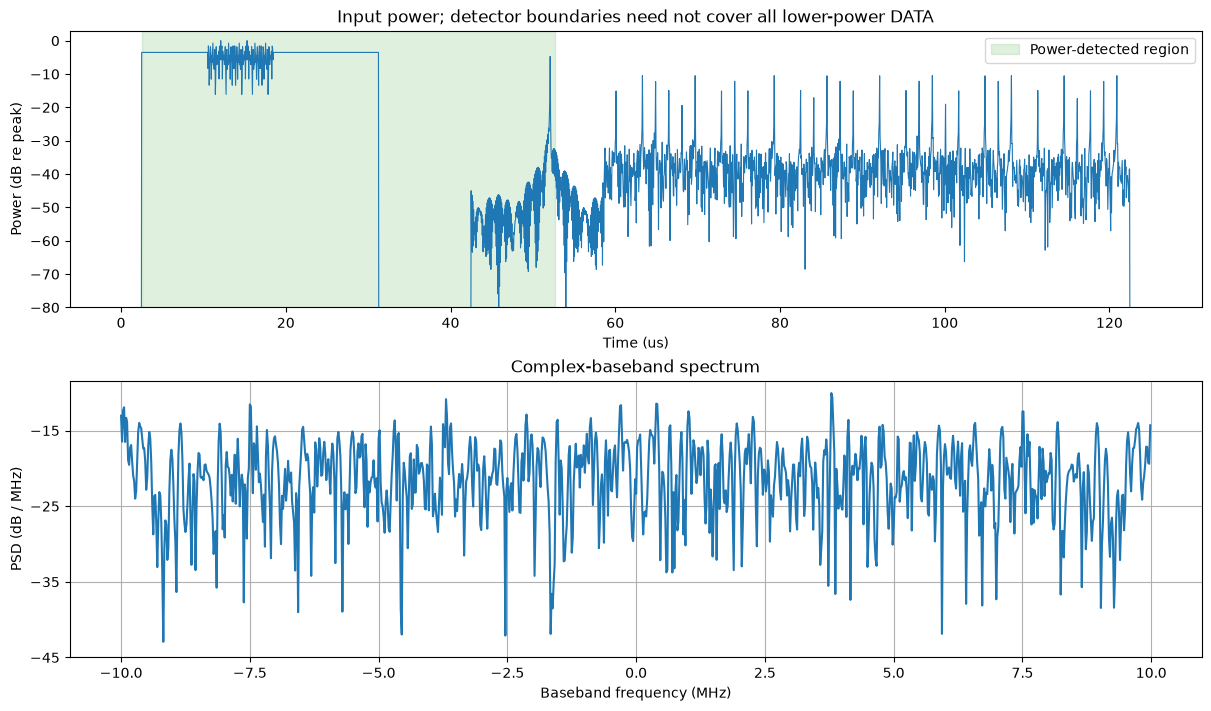

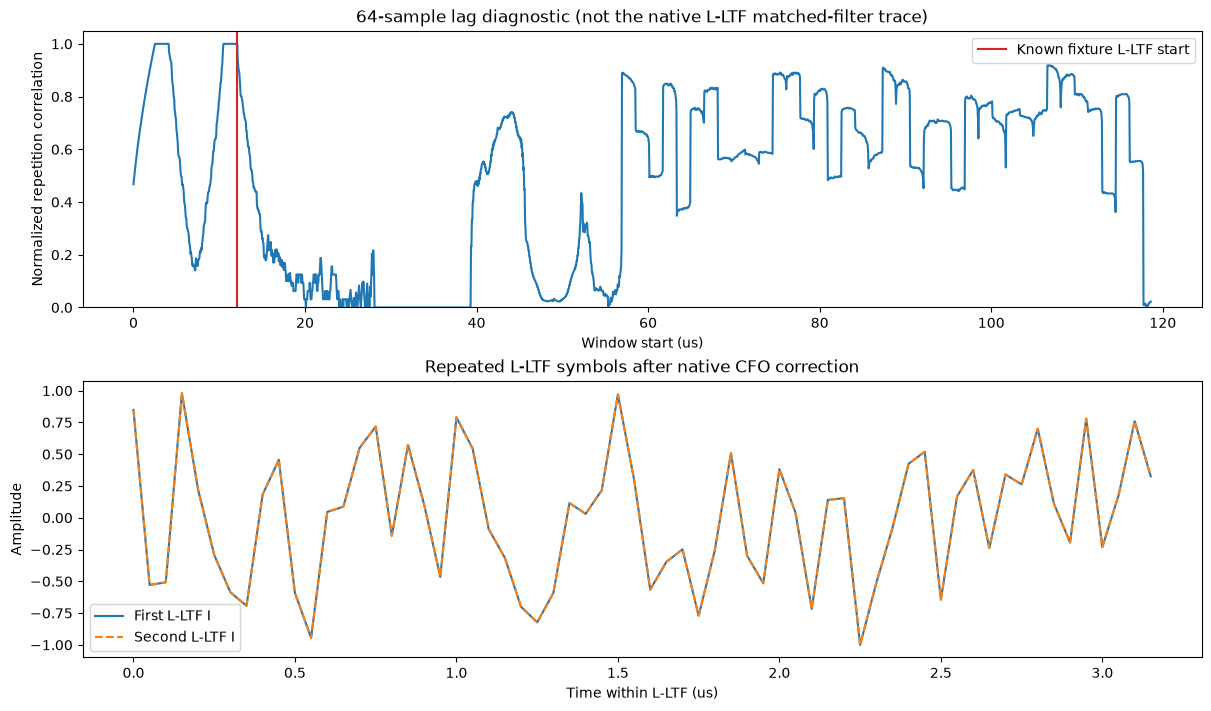

Native CFO estimate: 50000.000 Hz


In [3]:
# 3. Inspect input samples, spectrum, and legacy-LTF repetition.
time_us = np.arange(iq.size) / sample_rate * 1e6
power = np.abs(iq.astype(np.complex128)) ** 2
power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-12))
stride = max(1, iq.size // 25000)
figure, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(time_us[::stride], power_db[::stride], linewidth=0.8)
if result.burstFound:
    axes[0].axvspan(result.burstStart / sample_rate * 1e6,
                   (result.burstStart + result.burstLength) / sample_rate * 1e6,
                   color="tab:green", alpha=0.15, label="Power-detected region")
    axes[0].legend()
axes[0].set(xlabel="Time (us)", ylabel="Power (dB re peak)", ylim=(-80, 3),
            title="Input power; detector boundaries need not cover all lower-power DATA")
axes[1].psd(iq, NFFT=min(1024, iq.size), Fs=sample_rate / 1e6,
            sides="twosided", scale_by_freq=True)
axes[1].set(xlabel="Baseband frequency (MHz)", ylabel="PSD (dB / MHz)",
            title="Complex-baseband spectrum")
plt.show()

if np.isclose(sample_rate, 20e6) and iq.size >= 128:
    lag = 64
    first = iq[:-lag].astype(np.complex128)
    second = iq[lag:].astype(np.complex128)

    def moving_sum(values, length):
        cumulative = np.concatenate(([0], np.cumsum(values)))
        return cumulative[length:] - cumulative[:-length]

    cross = moving_sum(np.conj(first) * second, lag)
    first_energy = moving_sum(np.abs(first) ** 2, lag).real
    second_energy = moving_sum(np.abs(second) ** 2, lag).real
    energy = np.sqrt(np.maximum(first_energy, 0) * np.maximum(second_energy, 0))
    rho = np.divide(np.abs(cross), energy, out=np.zeros_like(energy),
                    where=energy > energy.max() * 1e-8)
    rho = np.clip(rho, 0, 1)
    correction = np.exp(-2j * np.pi * result.frequencyErrorHz * np.arange(iq.size) / sample_rate)
    corrected_iq = iq * correction
    figure, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
    axes[0].plot(np.arange(rho.size) / sample_rate * 1e6, rho)
    axes[0].set(xlabel="Window start (us)", ylabel="Normalized repetition correlation", ylim=(0, 1.05),
                title="64-sample lag diagnostic (not the native L-LTF matched-filter trace)")
    if capture is None:
        fixture_ppdu_start = 50
        legacy_fft_start = fixture_ppdu_start + 192
        axes[0].axvline(legacy_fft_start / sample_rate * 1e6, color="tab:red", label="Known fixture L-LTF start")
        axes[0].legend()
        legacy_first = corrected_iq[legacy_fft_start:legacy_fft_start + 64]
        legacy_second = corrected_iq[legacy_fft_start + 64:legacy_fft_start + 128]
        axes[1].plot(np.arange(64) / sample_rate * 1e6, legacy_first.real, label="First L-LTF I")
        axes[1].plot(np.arange(64) / sample_rate * 1e6, legacy_second.real, "--", label="Second L-LTF I")
        axes[1].set(xlabel="Time within L-LTF (us)", ylabel="Amplitude",
                    title="Repeated L-LTF symbols after native CFO correction")
    else:
        axes[1].plot(time_us[::stride], corrected_iq.real[::stride], linewidth=0.6, label="Corrected I")
        axes[1].set(xlabel="Time (us)", ylabel="Amplitude", title="Input after native CFO correction")
    axes[1].legend()
    plt.show()
    assert np.isfinite(rho).all() and np.isfinite(corrected_iq).all()
else:
    print("The 64-sample L-LTF diagnostic is restricted to 20 MSa/s inputs")
print(f"Native CFO estimate: {result.frequencyErrorHz:.3f} Hz")

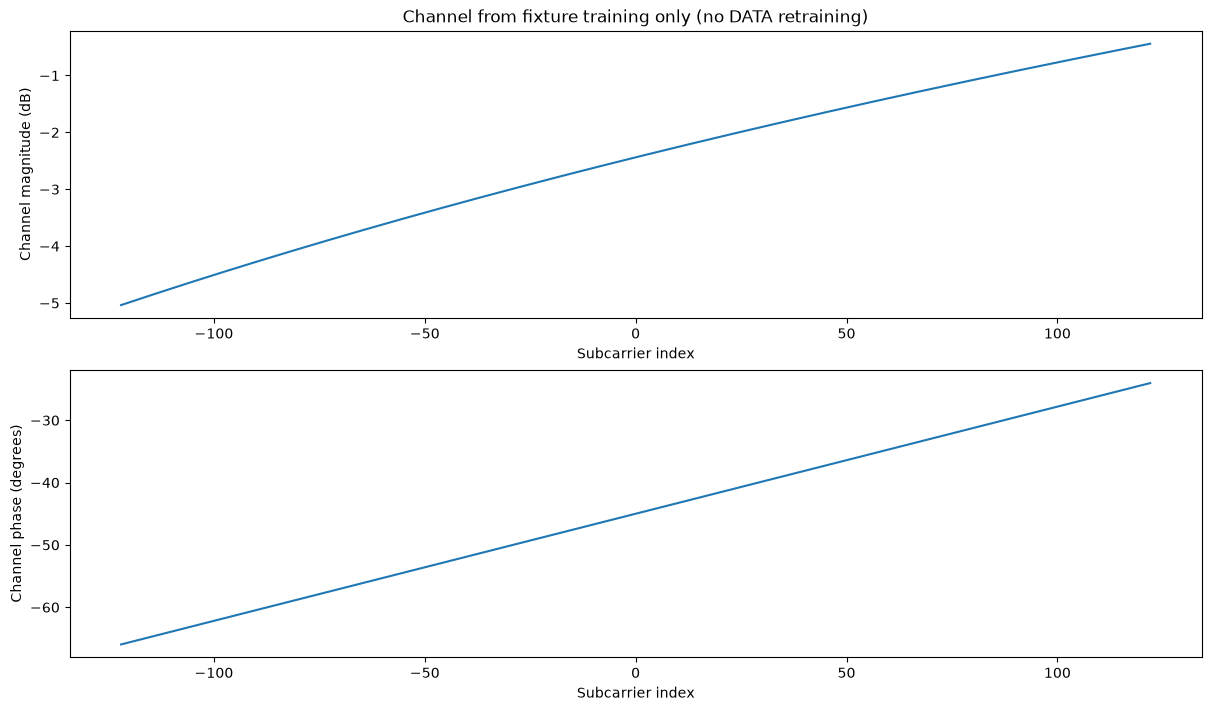

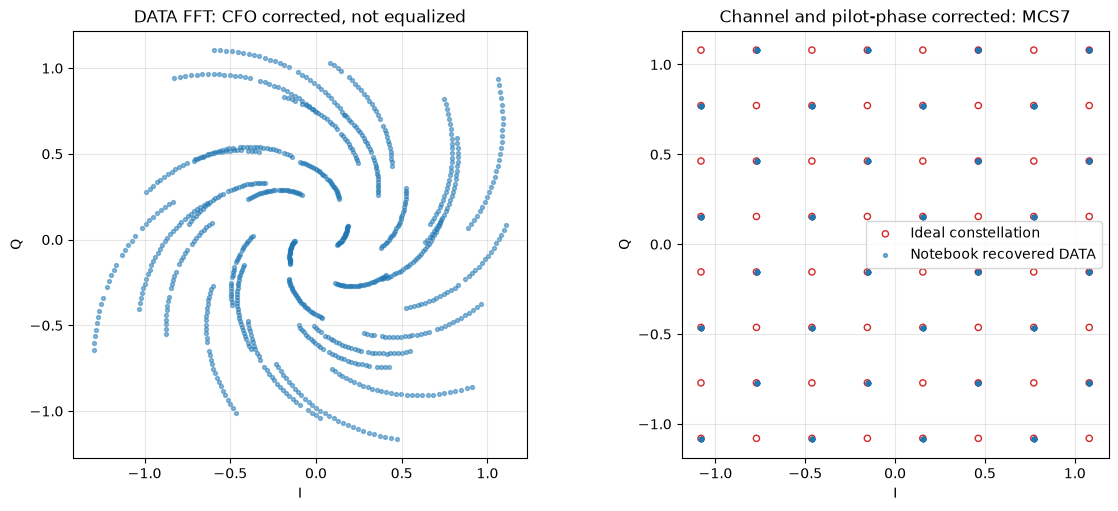

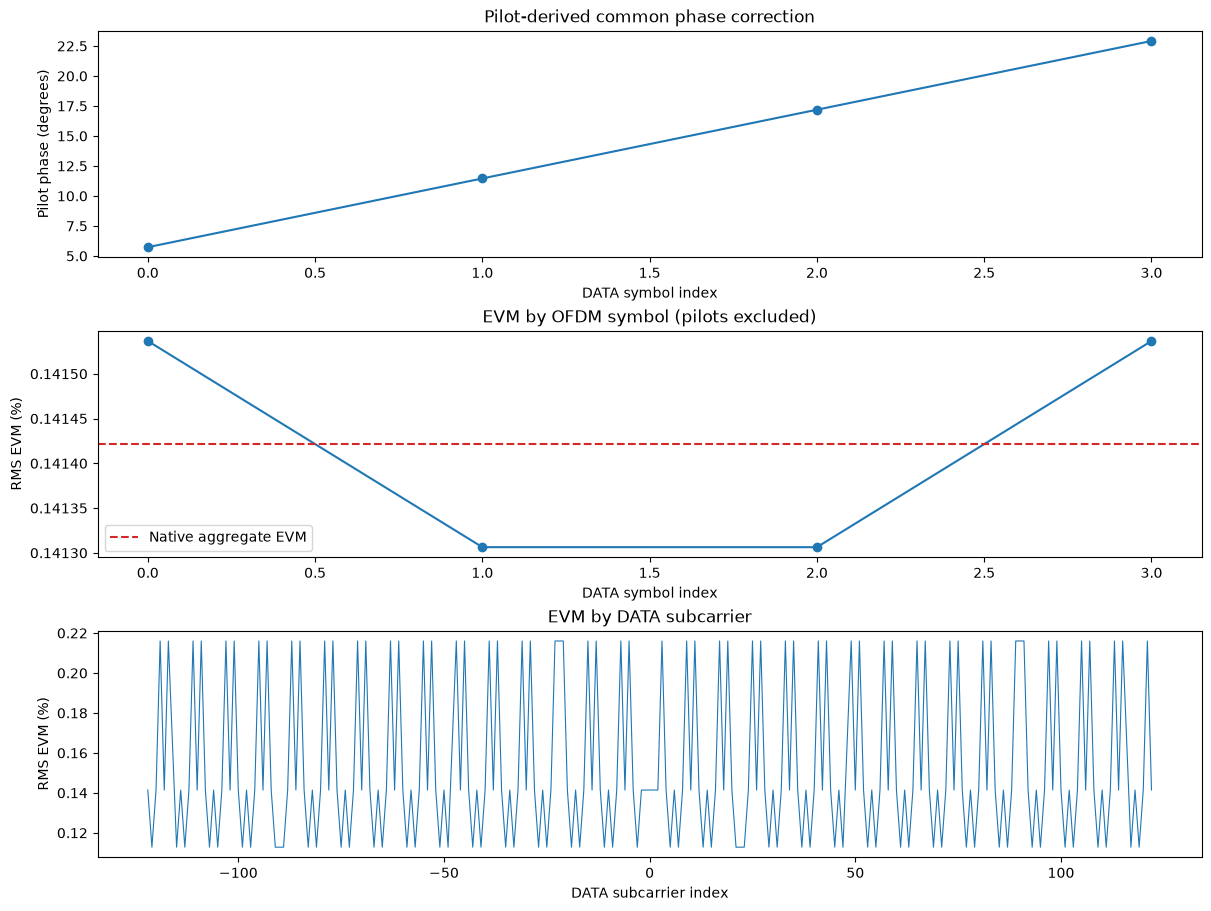

Notebook DATA EVM: 0.141421%
Native DATA EVM:   0.141421%
Known fixture EVM: 0.141421%
234 DATA tones x 4 symbols; pilot tones excluded
These are decision-directed symbols, not FEC-decoded payload bits or CRC results.


In [4]:
# 4. Inspect DATA processing using the independently known synthetic fixture layout.
# The wrapper returns scalar EVM only; these arrays are notebook calculations.
if capture is not None or not measure_data or not result.dataEvmValid:
    print("Fixture FFT/channel/constellation diagnostics skipped for file or sync-only input.")
    print("A real EHT capture requires its actual training sequence and packet layout.")
else:
    fixture_layout = (data_config.dataBandwidthMHz, data_config.numSpatialStreams,
                      data_config.ehtLtfType, data_config.ehtLtfFftOffsetSamples,
                      data_config.dataFftOffsetSamples, data_config.dataGuardIntervalSamples,
                      data_config.numDataSymbols)
    if fixture_layout != (20, 1, 4, 864, 1184, 64, 4):
        raise ValueError("Diagnostic plots require the unmodified regression fixture layout")
    tones = np.r_[np.arange(-122, -1), np.arange(2, 123)]
    bins = tones % 256
    pilot_mask = np.isin(np.abs(tones), [22, 48, 90, 116])
    data_mask = ~pilot_mask
    training_start = fixture_ppdu_start + data_config.ehtLtfFftOffsetSamples
    data_start = fixture_ppdu_start + data_config.dataFftOffsetSamples
    training_reference = np.where(bins % 2, -1.0, 1.0)
    training_fft = np.fft.fft(corrected_iq[training_start:training_start + 256])[bins]
    channel_estimate = training_fft / training_reference
    assert np.all(np.abs(channel_estimate) > 1e-9)
    symbol_spacing = 256 + data_config.dataGuardIntervalSamples
    received_fft = np.stack([
        np.fft.fft(corrected_iq[data_start + symbol * symbol_spacing:
                              data_start + symbol * symbol_spacing + 256])[bins]
        for symbol in range(data_config.numDataSymbols)
    ])
    equalized_before_phase = received_fft / channel_estimate
    pilot_phase = np.angle(np.mean(equalized_before_phase[:, pilot_mask], axis=1))
    equalized = equalized_before_phase * np.exp(-1j * pilot_phase[:, None])
    data_points = equalized[:, data_mask]
    bits = BITS_BY_MCS[data_config.dataMcs]
    levels = 2 if bits == 1 else 2 ** (bits // 2)
    scale = 1.0 if bits == 1 else np.sqrt(2 * (levels**2 - 1) / 3)
    decision_i = np.clip(np.rint((data_points.real * scale + levels - 1) / 2), 0, levels - 1)
    decision_i = (2 * decision_i - levels + 1) / scale
    if bits == 1:
        decisions = decision_i.astype(complex)
        ideal_points = np.array([-1, 1], dtype=complex)
    else:
        decision_q = np.clip(np.rint((data_points.imag * scale + levels - 1) / 2), 0, levels - 1)
        decision_q = (2 * decision_q - levels + 1) / scale
        decisions = decision_i + 1j * decision_q
        axis_levels = np.arange(-levels + 1, levels, 2) / scale
        ideal_points = (axis_levels[:, None] + 1j * axis_levels[None, :]).ravel()
    error_vectors = data_points - decisions
    reference_power = np.abs(decisions) ** 2
    error_power = np.abs(error_vectors) ** 2
    diagnostic_evm = np.sqrt(error_power.sum() / reference_power.sum())
    evm_by_symbol = 100 * np.sqrt(error_power.sum(axis=1) / reference_power.sum(axis=1))
    evm_by_tone = 100 * np.sqrt(error_power.sum(axis=0) / reference_power.sum(axis=0))
    np.testing.assert_allclose(diagnostic_evm, result.evmRmsData, atol=2e-6, rtol=0)

    figure, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
    axes[0].plot(tones, 20 * np.log10(np.abs(channel_estimate)))
    axes[0].set(xlabel="Subcarrier index", ylabel="Channel magnitude (dB)",
                title="Channel from fixture training only (no DATA retraining)")
    axes[1].plot(tones, np.rad2deg(np.unwrap(np.angle(channel_estimate))))
    axes[1].set(xlabel="Subcarrier index", ylabel="Channel phase (degrees)")
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    before = received_fft[:, data_mask].ravel()
    axes[0].scatter(before.real, before.imag, s=8, alpha=0.5)
    axes[0].set(title="DATA FFT: CFO corrected, not equalized", xlabel="I", ylabel="Q")
    axes[1].scatter(ideal_points.real, ideal_points.imag, s=20, facecolors="none",
                    edgecolors="tab:red", label="Ideal constellation")
    axes[1].scatter(data_points.real.ravel(), data_points.imag.ravel(), s=8,
                    alpha=0.6, label="Notebook recovered DATA")
    axes[1].set(title=f"Channel and pilot-phase corrected: MCS{data_config.dataMcs}", xlabel="I", ylabel="Q")
    axes[1].legend()
    for axis in axes:
        axis.set_aspect("equal", adjustable="box")
        axis.grid(True, alpha=0.3)
    plt.show()

    # 5. Compare the notebook's decision-directed EVM with the native scalar result.
    figure, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
    axes[0].plot(np.arange(data_config.numDataSymbols), np.rad2deg(pilot_phase), marker="o")
    axes[0].set(xlabel="DATA symbol index", ylabel="Pilot phase (degrees)", title="Pilot-derived common phase correction")
    axes[1].plot(np.arange(data_config.numDataSymbols), evm_by_symbol, marker="o")
    axes[1].axhline(100 * result.evmRmsData, color="tab:red", linestyle="--", label="Native aggregate EVM")
    axes[1].set(xlabel="DATA symbol index", ylabel="RMS EVM (%)", title="EVM by OFDM symbol (pilots excluded)")
    axes[1].legend()
    axes[2].plot(tones[data_mask], evm_by_tone, linewidth=0.8)
    axes[2].set(xlabel="DATA subcarrier index", ylabel="RMS EVM (%)", title="EVM by DATA subcarrier")
    plt.show()
    print(f"Notebook DATA EVM: {100 * diagnostic_evm:.6f}%")
    print(f"Native DATA EVM:   {100 * result.evmRmsData:.6f}%")
    print(f"Known fixture EVM: {100 * expected_evm:.6f}%")
    print(f"{data_points.shape[1]} DATA tones x {data_points.shape[0]} symbols; pilot tones excluded")
    print("These are decision-directed symbols, not FEC-decoded payload bits or CRC results.")

In [5]:
# 6. Validate the native measurement API separately from the visual walkthrough.
def validate_wifi7_api():
    """Known-error fixtures exercise Python -> C ABI -> native core for every MCS."""
    layout = demod.WifiBeDataConfig()
    outcomes = []
    for mcs in range(14):
        for noise in (0.0, 0.001):
            samples, expected = make_data_fixture(mcs, noise)
            measured = demod.demodulate(demod.WIFI_BE, samples, demod.Config(sampleRate=20e6),
                                        data_config=replace(layout, dataMcs=mcs))
            assert measured.ok and measured.syncFound and measured.dataEvmValid, measured.as_dict()
            assert measured.numDataSymbols == 4
            np.testing.assert_allclose(measured.evmRmsData, expected, atol=2e-6, rtol=0)
            outcomes.append((mcs, noise, measured.evmRmsData * 100))
    samples, _ = make_data_fixture(7)
    for unsupported in (replace(layout, dataBandwidthMHz=40),
                        replace(layout, numSpatialStreams=2), replace(layout, ehtLtfType=2),
                        replace(layout, dataMcs=14)):
        rejected = demod.demodulate(demod.WIFI_BE, samples, config=demod.Config(sampleRate=20e6),
                                    data_config=unsupported)
        assert not rejected.dataEvmValid and rejected.dataError
        assert "evmRmsData" not in rejected.as_dict()
    truncated = demod.demodulate(demod.WIFI_BE, samples[:-178], demod.Config(sampleRate=20e6),
                                 data_config=layout)
    assert not truncated.dataEvmValid and truncated.dataError
    sync_only = demod.demodulate(demod.WIFI_BE, samples, demod.Config(sampleRate=20e6))
    assert sync_only.ok and sync_only.syncFound and not sync_only.dataEvmValid
    empty = demod.demodulate(demod.WIFI_BE, np.empty(0, dtype=complex),
                             demod.Config(sampleRate=20e6), data_config=layout)
    assert not empty.ok and not empty.dataEvmValid
    try:
        demod.demodulate(demod.WIFI_A, samples, demod.Config(sampleRate=20e6), data_config=layout)
    except ValueError:
        pass
    else:
        raise AssertionError("Other families must reject Wi-Fi 7 DATA configuration")
    print(f"Passed {len(outcomes)} DATA/EVM cases plus rejection and sync-only checks")
    return outcomes


validation_results = validate_wifi7_api()
print("No U-SIG/EHT-SIG decoding, FEC-decoded payload bits, or CRC verification is performed.")

Passed 28 DATA/EVM cases plus rejection and sync-only checks
No U-SIG/EHT-SIG decoding, FEC-decoded payload bits, or CRC verification is performed.
